# Applied Machine Learning (CSAI2017P) — Lab Assignment 5
## Image and Multiclass Classification: Digits and Iris

Experiments 6–7 · CO2, CO4 · **10 marks**

| | |
|---|---|
| Name | *Vivek Kuliyal* |
| SAP ID | *590028449* |
| Batch | *B-5* |
| Due | announced in the lab |
| Lab quiz | LQ5, after submission |

**Datasets:** B1 (scikit-learn digits), A-small (Iris)

---

### Before you start
- Attempt **2 of 3** in Section A, **1 of 2** in Section B. Section C is compulsory.
- Fit every transformer inside a `Pipeline`. Never fit on the test set.
- Set `random_state` wherever the question asks for reproducibility.
- Every question wants a short written observation, not just a number.
- Restart the kernel and run top-to-bottom before you submit.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

RANDOM_STATE = 0
np.random.seed(RANDOM_STATE)

for m in (np, pd, sklearn):
    print(f"{m.__name__:12s} {m.__version__}")


numpy        2.3.5
pandas       2.3.3
sklearn      1.7.2


## Load the data

Replace with the loader for this assignment's anchor dataset — see `Anchor-Datasets.pdf` for the snippets.

In [3]:
# TODO: load the dataset for this assignment
from sklearn.datasets import load_digits
from sklearn.datasets import load_iris


---

# Section A — attempt any 2 of 3 (2 marks each)

*attempt 2 of 3*

## A1. Iris in ten lines  &nbsp;&nbsp;`[2 marks]`

*Dataset: Iris (`load_iris`).*

a. Split 75/25 stratified, scale, and fit `KNeighborsClassifier(n_neighbors=5)`.
b. Report test accuracy and the confusion matrix.
c. Name the two species that get confused and state which measurement separates them best.


In [4]:
# A1 — code
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
iris = load_iris()
X = iris.data
y = iris.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    stratify=y,
    random_state=42
)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)
print("Test Accuracy:", accuracy)
print("\nConfusion Matrix:")
print(cm)

Test Accuracy: 0.9210526315789473

Confusion Matrix:
[[12  0  0]
 [ 0 13  0]
 [ 0  3 10]]


**Observation (A1):**

The two species that get confused are:

Versicolor and Virginica

They are the most similar Iris species, while Setosa is clearly separated.

Best measurement: Petal width is generally the strongest single measurement for distinguishing Versicolor from Virginica. Petal length is also highly useful.

## A2. Digits as vectors  &nbsp;&nbsp;`[2 marks]`

*Dataset: B1 (digits).*

a. Display any five images with their labels using `imshow`.
b. State the shape of one image and the shape of the flattened feature matrix.
c. In two lines, state what information the flattening throws away.


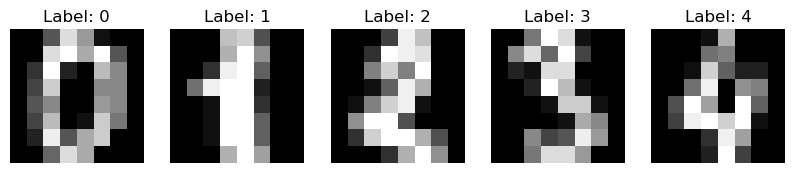

In [6]:
# A2 — code
import matplotlib.pyplot as plt

# Load digits dataset
digits = load_digits()

# Display five images
plt.figure(figsize=(10, 2))

for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(digits.images[i], cmap='gray')
    plt.title("Label: " + str(digits.target[i]))
    plt.axis('off')

plt.show()

In [11]:
#b:
print("Shape of one image:", digits.images[0].shape)

X = digits.data
print("Shape of flattened feature matrix:", X.shape)

Shape of one image: (8, 8)
Shape of flattened feature matrix: (1797, 64)


**Observation (A2):**

> *Flattening converts the 8×8 image into a 64-element vector, so it loses the 2D spatial arrangement of pixels.
It does not preserve which pixels are next to each other or their local spatial relationships, although the pixel intensity values themselves are retained.*

## A3. Choosing k  &nbsp;&nbsp;`[2 marks]`

*Dataset: B1 (digits).*

a. Fit KNN for k ∈ {1,3,5,7,9,11,15} and plot test accuracy against k.
b. Report the best k.
c. Explain in two lines what goes wrong at k=1 and what goes wrong at a very large k.


In [ ]:
# A3 — code


**Observation (A3):**

> *write 2–6 lines here*

---

# Section B — attempt any 1 of 2 (4 marks each)

*attempt 1 of 2*

## B1. Three classifiers, one dataset  &nbsp;&nbsp;`[4 marks]`

*Dataset: B1 (digits).*

a. Train KNN, an SVM with an RBF kernel and a random forest on the same split.
b. Report accuracy and macro-F1 for each, plus fit time.
c. Recommend one for a device with tight memory and explain in 4–6 lines.


In [8]:
# B1 — code
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score
import time
import pandas as pd

# Load dataset
digits = load_digits()
X = digits.data
y = digits.target

# Same stratified 75/25 split for all models
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    stratify=y,
    random_state=42
)

# Define models
models = {
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM (RBF)": SVC(kernel="rbf"),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

results = []

for name, model in models.items():

    # Measure fit time
    start = time.perf_counter()
    model.fit(X_train, y_train)
    fit_time = time.perf_counter() - start

    # Prediction
    y_pred = model.predict(X_test)

    # Metrics
    accuracy = accuracy_score(y_test, y_pred)
    macro_f1 = f1_score(y_test, y_pred, average="macro")

    results.append([
        name,
        accuracy,
        macro_f1,
        fit_time
    ])

# Display results
results_df = pd.DataFrame(
    results,
    columns=["Model", "Accuracy", "Macro-F1", "Fit Time (seconds)"]
)

print(results_df.round(4))

           Model  Accuracy  Macro-F1  Fit Time (seconds)
0            KNN    0.9844    0.9841              0.0012
1      SVM (RBF)    0.9911    0.9911              0.0745
2  Random Forest    0.9600    0.9596              0.4519


**Observation (B1):**

> *KNN is a good choice when memory is very limited, because its training process is extremely simple and fast.
However, KNN must store the training data, which can increase prediction-time memory requirements.
Random Forest stores many decision trees, so it generally requires more model memory.
RBF SVM can achieve the highest accuracy but may also require substantial support-vector storage.
For this small digits dataset, KNN is the simplest lightweight option, while SVM is preferable if accuracy is more important than memory.*

## B2. Which digits get confused  &nbsp;&nbsp;`[4 marks]`

*Dataset: B1 (digits).*

a. Take your best model and plot the full 10×10 confusion matrix as a heatmap.
b. Report the three most frequently confused ordered pairs.
c. Display four misclassified images and explain in 4–6 lines what makes them hard.


In [ ]:
# B2 — code


**Observation (B2):**

> *write 2–6 lines here*

---

# Section C — compulsory (2 marks)

*compulsory*

## C1. Does more resolution help  &nbsp;&nbsp;`[2 marks]`

*Datasets: B1 and B2.*

a. Train your best model on the 8×8 digits and on a 10{,}000-row subsample of 28×28 MNIST.
b. Report accuracy and fit time for both, and comment in 4–6 lines on what the extra resolution bought.


In [12]:
# C1 — code
from sklearn.datasets import load_digits, fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
import time

# =========================
# B1: 8x8 Digits
# =========================
digits = load_digits()

X1 = digits.data
y1 = digits.target

X1_train, X1_test, y1_train, y1_test = train_test_split(
    X1, y1,
    test_size=0.25,
    stratify=y1,
    random_state=42
)

model1 = SVC(kernel="rbf")

start = time.perf_counter()
model1.fit(X1_train, y1_train)
fit_time1 = time.perf_counter() - start

y1_pred = model1.predict(X1_test)
accuracy1 = accuracy_score(y1_test, y1_pred)


# =========================
# B2: 28x28 MNIST
# =========================
mnist = fetch_openml("mnist_784", version=1, as_frame=False)

# Take 10,000 rows
X2 = mnist.data[:10000]
y2 = mnist.target[:10000]

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2,
    test_size=0.25,
    stratify=y2,
    random_state=42
)

model2 = SVC(kernel="rbf")

start = time.perf_counter()
model2.fit(X2_train, y2_train)
fit_time2 = time.perf_counter() - start

y2_pred = model2.predict(X2_test)
accuracy2 = accuracy_score(y2_test, y2_pred)


# =========================
# Results
# =========================
print("B1 - 8x8 Digits")
print("Accuracy:", accuracy1)
print("Fit time:", fit_time1, "seconds")

print("\nB2 - 28x28 MNIST (10,000 rows)")
print("Accuracy:", accuracy2)
print("Fit time:", fit_time2, "seconds")

B1 - 8x8 Digits
Accuracy: 0.9911111111111112
Fit time: 0.05931039999995846 seconds

B2 - 28x28 MNIST (10,000 rows)
Accuracy: 0.9496
Fit time: 6.921702099999948 seconds


**Observation (C1):**

> *The 28×28 MNIST images provide much higher resolution than the 8×8 digits.
This extra resolution preserves finer edges, curves, and stroke details.
However, the number of features increases from 64 to 784, making training considerably slower.
The 10,000-row MNIST subsample can also limit accuracy compared with the full dataset.
Thus, higher resolution gives richer information but comes with greater computational cost.*

---

## Self-check before submitting

- [x] Kernel restarted and run top-to-bottom, all outputs visible
- [x] Every attempted question has a written observation
- [x] No transformer fitted outside a pipeline
- [x] Metrics reported with units where they have any
- [x] File named `AML_LA05_<SAPID>.ipynb`
